In [1]:
import pandas as pd
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt

fits_file = 'chandra_COSMOS_legacy_opt_NIR_counterparts_20160113_4d.fits'
hdul = fits.open(fits_file)
df = pd.DataFrame(hdul[1].data)

df.replace(-99.000, np.nan, inplace=True)
df.replace(-99, np.nan, inplace=True)

# Filter for valid spectroscopic redshifts (z_spec)
mask_valid_z = (df['z_spec'].notna()) # & (df['z_spec'] > 0) # Add (df['Qg'] >= 1.5))
df_z = df[mask_valid_z].copy()

print(f"Total sources with valid z_spec: {len(df_z)}")

# Show all columns
pd.set_option('display.max_columns', None)
df.head(3)

Total sources with valid z_spec: 2287


,id_x,RA_x,DEC_x,DET_ML_F,DET_ML_S,DET_ML_H,flux_F,flux_S,flux_H,HR,HR_lo_lim,HR_up_lim,id_i,ra_i,dec_i,i_mag,i_mag_err,flag_i_mag,id_k_uv,ra_k_uv,dec_k_uv,k_uv_mag,k_uv_mag_err,id_k_cfht,ra_k_cfht,dec_k_cfht,k_cfht_mag,k_cfht_mag_err,ra_irac,dec_irac,irac_mag,irac_mag_err,ra_splash,dec_splash,splash_mag,splash_mag_err,final_id_flag,star_flag,z_best,z_spec,Instr,Qg,spec_type,z_phot,phot_type,id_xmm,dist_lum,Lx_0510,Lx_052,Lx_210,NH,abs_corr_0510,abs_corr_052,abs_corr_210,NH_lo,abs_corr_0510_lo,abs_corr_052_lo,abs_corr_210_lo,NH_up,abs_corr_0510_up,abs_corr_052_up,abs_corr_210_up
0,cid_1,149.63956,1.991034,10.910000,NaN,NaN,1.180000e-15,-3.940000e-16,-1.120000e-14,NaN,0.52,NaN,860777.0,149.639496,1.991038,26.059999,0.22,1.0,455942.0,149.639513,1.991030,22.110001,0.03,860777.0,149.639481,1.991048,22.180000,0.05,149.639435,1.991108,21.639999,0.01,149.639513,1.991030,21.420000,0.01,1.0,0,1.928,NaN,None,0.0,-9.0,1.928,3.0,NaN,15123.339844,43.229000,-42.752998,-44.206001,NaN,NaN,NaN,NaN,39.200001,0.531,0.081,0.796,NaN,NaN,NaN,NaN
1,cid_100,150.34101,2.367167,353.079987,284.350006,82.540001,1.430000e-14,3.670000e-15,9.880000e-15,-0.27,-0.39,-0.13,1210176.0,150.341034,2.367181,23.620001,0.03,1.0,704286.0,150.341070,2.367165,21.270000,0.01,1210176.0,150.341049,2.367159,21.309999,0.03,150.341049,2.367121,20.850000,0.01,150.341070,2.367165,20.590000,0.01,1.0,0,1.590,1.59,VIMOS,1.5,1.0,1.572,1.0,320.0,11920.509766,44.138000,43.547001,43.977001,0.0,1.0,1.0,1.0,0.000000,1.000,1.000,1.000,4.46,0.769,0.438,0.964
2,cid_1000,149.67574,2.010529,124.730003,141.699997,NaN,6.850000e-15,2.050000e-15,-1.320000e-14,NaN,NaN,-0.91,857679.0,149.675766,2.010352,24.190001,0.05,1.0,470092.0,149.675807,2.010416,21.240000,0.01,857679.0,149.675812,2.010447,21.540001,0.03,149.675766,2.010402,20.830000,0.01,149.675807,2.010416,20.530001,0.01,1.0,0,1.847,NaN,None,0.0,-9.0,1.847,3.0,5355.0,14344.620117,43.953999,43.430000,-44.238998,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,1.000,1.000,1.000


## Histogram of z_spec (all)

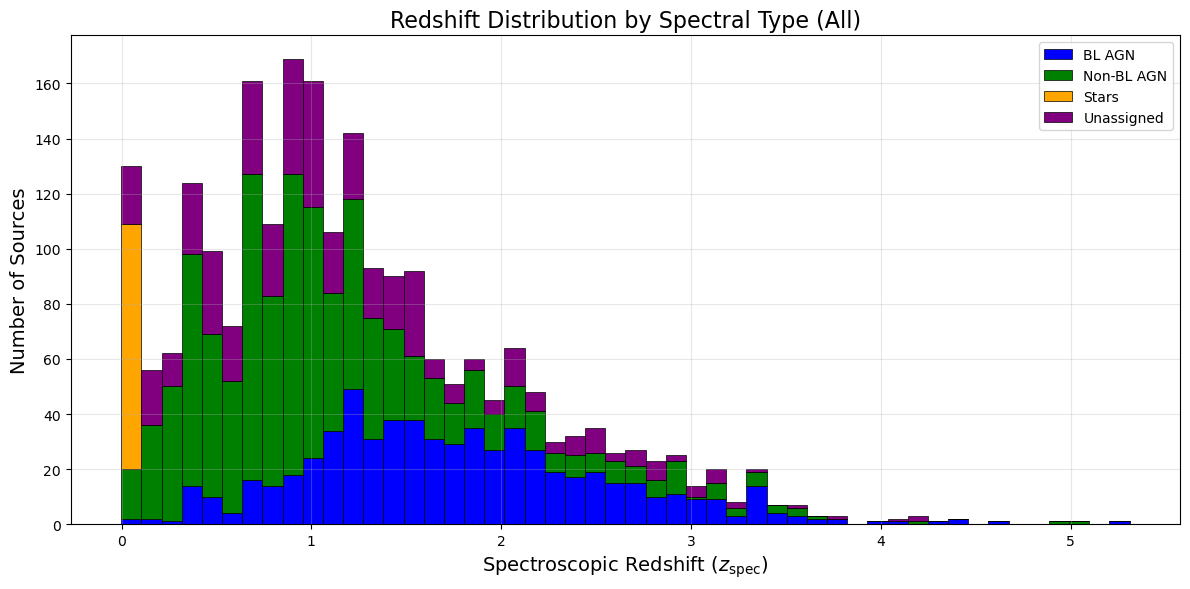

Min z_spec: -0.0010000000474974513
Max z_spec: 5.309999942779541


In [2]:
plt.figure(figsize=(12, 6))

# Define mask for each category
mask_bl = df_z['spec_type'] == 1
mask_non_bl = df_z['spec_type'] == 2
mask_star = df_z['spec_type'] == 0
mask_unassigned = ~(df_z['spec_type'].isin([0, 1, 2]))

# Plot each category with transparency to see overlaps
bins = 50

plt.hist([df_z.loc[mask_bl, 'z_spec'].dropna(), 
          df_z.loc[mask_non_bl, 'z_spec'].dropna(), 
          df_z.loc[mask_star, 'z_spec'].dropna(), 
          df_z.loc[mask_unassigned, 'z_spec'].dropna()], 
         bins=bins, 
         stacked=True, 
         color=['blue', 'green', 'orange', 'purple'], 
         edgecolor='black', 
         linewidth=0.5, 
         label=['BL AGN', 'Non-BL AGN', 'Stars', 'Unassigned'])

# Formatting
plt.xlabel('Spectroscopic Redshift ($z_{\\rm spec}$)', fontsize=14)
plt.ylabel('Number of Sources', fontsize=14)
plt.title('Redshift Distribution by Spectral Type (All)', fontsize=16)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Min z_spec: {df_z['z_spec'].min()}")
print(f"Max z_spec: {df_z['z_spec'].max()}")